# Explorer 02 - Genres and styles

**Purpose.** Explore how genre and style composition moved from 2016 to 2026 and choose the fragmentation measure.

**Feeds main report section:** 5.1 RQ1 - Genre and style shifts

**Modules used:** `vinyl.trends`, `vinyl.viz`

**Tables read:** `release_genres`, `release_styles`

This is a working notebook. It can be messy; anything that goes into the report is re-run from `main.ipynb` through the same functions in `vinyl/`.

In [1]:
# Make the `vinyl` package importable from the explorers/ folder.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "explorers":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

from pyspark.sql import functions as F
from vinyl import config, ingest

spark = ingest.get_spark(app_name="vinyl-02-styles")
from vinyl import trends, viz

In [2]:
snapshot = config.MAIN_SNAPSHOT  # "2026"
release_genres = ingest.read_table(spark, snapshot, "release_genres")
release_styles = ingest.read_table(spark, snapshot, "release_styles")
release_artists = ingest.read_table(spark, snapshot, "release_artists")

## 1. Coverage: how many releases have a genre or style at all?

In [3]:
releases = ingest.read_table(spark, snapshot, "releases")
total = releases.groupBy("year").agg(F.count("*").alias("n_all"))
tagged = release_styles.groupBy("year").agg(F.countDistinct("release_id").alias("n_with_style"))
total.join(tagged, "year", "left").withColumn("coverage", F.col("n_with_style") / F.col("n_all")).orderBy("year").show()

+----+------+------------+------------------+
|year| n_all|n_with_style|          coverage|
+----+------+------------+------------------+
|2016|385281|      339745|0.8818109379907133|
|2017|390355|      343757|0.8806266091122184|
|2018|396710|      351726| 0.886607345416047|
|2019|394016|      348461| 0.884382867700804|
|2020|415671|      370616|0.8916089888397314|
|2021|391297|      348376| 0.890310940283212|
|2022|360863|      321938| 0.892133579779584|
|2023|347065|      311875|0.8986068891994295|
|2024|312179|      281021|0.9001918770961531|
|2025|280882|      254196|0.9049921319272862|
|2026|154790|      141806|0.9161186123134569|
+----+------+------------+------------------+



## 2. Genre and style shares by year

<Axes: title={'left': "Share of each year's releases tagged with each genre (2026 is partial: Jan-Sep)"}, xlabel='year', ylabel='share of releases'>

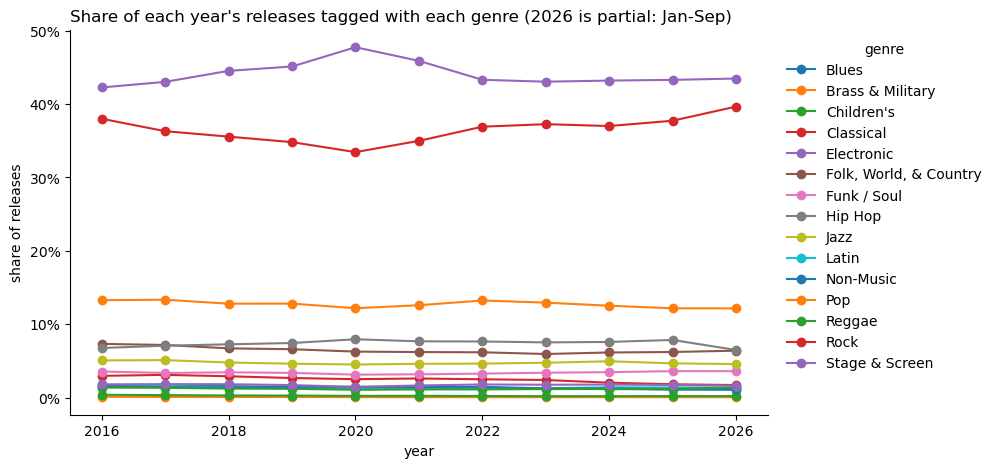

In [4]:
genre_shares = trends.tag_shares_by_year(release_genres, tag_col="genre").toPandas()
viz.plot_lines(
    genre_shares, "year", "share", "genre",
    title="Share of each year's releases tagged with each genre (2026 is partial: Jan-Sep)",
    ylabel="share of releases", percent=True,
)

In [5]:
style_shares = trends.tag_shares_by_year(release_styles, tag_col="style")
start_year, last_full, prev_year = 2016, config.LAST_FULL_YEAR, config.LAST_FULL_YEAR - 1
movers = {
    end: trends.top_movers(style_shares, start_year=start_year, end_year=end, min_releases=500).toPandas()
    for end in (last_full, prev_year)
}
for end, df in movers.items():
    print(f"Style share change {start_year} -> {end}: 15 largest gains, then 15 largest losses")
    display(df.head(15))
    display(df.tail(15))

# Does the cataloguing lag in the last full year change the ranking?
rank = {end: df.set_index("style")["change"].rank(ascending=False) for end, df in movers.items()}
both = rank[last_full].to_frame(f"rank_{last_full}").join(rank[prev_year].rename(f"rank_{prev_year}"), how="inner")
top = {end: set(df.head(15)["style"]) for end, df in movers.items()}
print(f"Spearman rank correlation of the change, {last_full} vs {prev_year} end year: "
      f"{both.corr(method='spearman').iloc[0, 1]:.3f}")
print(f"Styles in both top-15 gain lists: {len(top[last_full] & top[prev_year])} of 15")

Style share change 2016 -> 2025: 15 largest gains, then 15 largest losses


,style,share_start,n_start,share_end,n_end,change
0,Hardcore,0.040042,13604,0.051106,12991,0.011064
1,Alt-Pop,0.000409,139,0.010291,2616,0.009882
2,Black Metal,0.030346,10310,0.037503,9533,0.007156
3,Hardstyle,0.006225,2115,0.012022,3056,0.005797
4,Dungeon Synth,0.001507,512,0.006884,1750,0.005377
5,Dream Pop,0.001174,399,0.005893,1498,0.004719
6,Goregrind,0.001707,580,0.006393,1625,0.004686
7,Noise Rock,0.000430,146,0.004902,1246,0.004472
8,Indie Pop,0.019232,6534,0.023470,5966,0.004238
9,Alternative Metal,0.000386,131,0.004622,1175,0.004237


,style,share_start,n_start,share_end,n_end,change
211,Progressive Trance,0.010805,3671,0.006078,1545,-0.004727
212,Electro,0.027376,9301,0.022286,5665,-0.005090
213,Vaporwave,0.011827,4018,0.006703,1704,-0.005123
214,Drone,0.021045,7150,0.015720,3996,-0.005325
215,Pop Rock,0.023768,8075,0.018435,4686,-0.005333
216,Dubstep,0.010172,3456,0.004760,1210,-0.005412
217,Punk,0.056442,19176,0.050976,12958,-0.005466
218,Minimal,0.014982,5090,0.008958,2277,-0.006024
219,Downtempo,0.022058,7494,0.015921,4047,-0.006137
220,Vocal,0.011868,4032,0.005626,1430,-0.006242


Style share change 2016 -> 2024: 15 largest gains, then 15 largest losses


,style,share_start,n_start,share_end,n_end,change
0,Hardcore,0.040042,13604,0.048712,13689,0.008670
1,Black Metal,0.030346,10310,0.038513,10823,0.008167
2,Alt-Pop,0.000409,139,0.008131,2285,0.007722
3,Dungeon Synth,0.001507,512,0.008522,2395,0.007015
4,Death Metal,0.021763,7394,0.028692,8063,0.006928
5,Hardstyle,0.006225,2115,0.010732,3016,0.004507
6,Breakbeat,0.005854,1989,0.010035,2820,0.004180
7,Dream Pop,0.001174,399,0.005238,1472,0.004064
8,Noise Rock,0.000430,146,0.004491,1262,0.004061
9,Jungle,0.003338,1134,0.007345,2064,0.004007


,style,share_start,n_start,share_end,n_end,change
212,Downtempo,0.022058,7494,0.017696,4973,-0.004362
213,Deep House,0.030231,10271,0.025788,7247,-0.004443
214,Progressive Trance,0.010805,3671,0.006110,1717,-0.004695
215,Punk,0.056442,19176,0.051615,14505,-0.004827
216,Noise,0.037045,12586,0.032147,9034,-0.004898
217,Tech House,0.025637,8710,0.020621,5795,-0.005016
218,Electro,0.027376,9301,0.022205,6240,-0.005172
219,Abstract,0.018952,6439,0.013529,3802,-0.005423
220,Vocal,0.011868,4032,0.005978,1680,-0.005890
221,Pop Rock,0.023768,8075,0.017835,5012,-0.005933


Spearman rank correlation of the change, 2025 vs 2024 end year: 0.926
Styles in both top-15 gain lists: 12 of 15


### 2b. Robustness: drop the prolific artists

A few real artists self-release hundreds or thousands of releases in one year. In 2026, 35 artist-years reach `config.PROLIFIC_ARTIST_MIN_PER_YEAR` (300) releases, 0.4% of all releases, so totals barely move. Niche styles can: artist 6351861 alone is 22% of the 2019 "Harsh Noise Wall" releases and 27% of 2023.

The next cell recomputes the style shares and `top_movers` without the releases of those artist-years (`trends.drop_prolific_releases`). This is a robustness check, not the main definition. The main ranking stays the one above.

Reading rule:

- If a style's `change` shrinks a lot once the prolific artists are dropped, that style's trend is one artist's output, not a scene. Say so next to the style in the report.
- If the styles and the size of `change` stay about the same, the trend does not depend on them.
- A Spearman correlation close to 1 means the ranking as a whole is stable. Check the top and bottom 15 directly, because the correlation is dominated by the many styles in the middle.

In [6]:
import pandas as pd

prolific = trends.prolific_artist_years(release_artists).cache()
styles_clean = trends.drop_prolific_releases(release_styles, release_artists, prolific)
shares_clean = trends.tag_shares_by_year(styles_clean, tag_col="style")
movers_clean = trends.top_movers(shares_clean, start_year=start_year, end_year=last_full, min_releases=500).toPandas()
movers_main = movers[last_full]

def side_by_side(main, clean):
    """Put the main and the prolific-dropped ranking next to each other."""
    left = main[["style", "change"]].reset_index(drop=True).add_suffix("_main")
    right = clean[["style", "change"]].reset_index(drop=True).add_suffix("_no_prolific")
    return left.join(right)

print(f"Style share change {start_year} -> {last_full}: main ranking (left) vs without prolific artists (right)")
print("15 largest gains")
display(side_by_side(movers_main.head(15), movers_clean.head(15)))
print("15 largest losses")
display(side_by_side(movers_main.tail(15), movers_clean.tail(15)))

# Change of the main top and bottom 15 once the prolific artists are dropped.
watch = pd.concat([movers_main.head(15), movers_main.tail(15)])[["style", "change"]]
watch = watch.merge(movers_clean[["style", "change"]], on="style", how="left", suffixes=("_main", "_no_prolific"))
watch["shrunk_by"] = watch["change_main"].abs() - watch["change_no_prolific"].abs()
print("Styles of the main top/bottom 15, largest shrinkage first")
display(watch.sort_values("shrunk_by", ascending=False).head(10))

both = movers_main.set_index("style")["change"].to_frame("main").join(movers_clean.set_index("style")["change"].rename("no_prolific"), how="inner")
print(f"Spearman correlation of the change, main vs without prolific artists: {both.corr(method='spearman').iloc[0, 1]:.3f} ({len(both)} styles in both)")

print(f"Prolific artist-years (>= {config.PROLIFIC_ARTIST_MIN_PER_YEAR} releases in one year)")
display(prolific.toPandas().sort_values("n_releases", ascending=False))

Style share change 2016 -> 2025: main ranking (left) vs without prolific artists (right)
15 largest gains


,style_main,change_main,style_no_prolific,change_no_prolific
0,Hardcore,0.011064,Hardcore,0.011137
1,Alt-Pop,0.009882,Alt-Pop,0.009932
2,Black Metal,0.007156,Black Metal,0.007205
3,Hardstyle,0.005797,Hardstyle,0.005829
4,Dungeon Synth,0.005377,Dungeon Synth,0.005405
5,Dream Pop,0.004719,Dream Pop,0.004743
6,Goregrind,0.004686,Goregrind,0.004710
7,Noise Rock,0.004472,Noise Rock,0.004495
8,Indie Pop,0.004238,Indie Pop,0.004268
9,Alternative Metal,0.004237,Alternative Metal,0.004261


15 largest losses


,style_main,change_main,style_no_prolific,change_no_prolific
0,Progressive Trance,-0.004727,Tech House,-0.005006
1,Electro,-0.005090,Electro,-0.005098
2,Vaporwave,-0.005123,Vaporwave,-0.005144
3,Drone,-0.005325,Ambient,-0.005306
4,Pop Rock,-0.005333,Dubstep,-0.005435
5,Dubstep,-0.005412,Punk,-0.005463
6,Punk,-0.005466,Minimal,-0.006048
7,Minimal,-0.006024,Downtempo,-0.006141
8,Downtempo,-0.006137,Vocal,-0.006245
9,Vocal,-0.006242,Abstract,-0.006404


Styles of the main top/bottom 15, largest shrinkage first


,style,change_main,change_no_prolific,shrunk_by
10,Progressive House,0.004076,0.003068,0.001008
19,Pop Rock,-0.005333,-0.004874,0.000459
21,Punk,-0.005466,-0.005463,0.000003
24,Vocal,-0.006242,-0.006245,-0.000003
23,Downtempo,-0.006137,-0.006141,-0.000004
16,Electro,-0.005090,-0.005098,-0.000008
26,Abstract,-0.006391,-0.006404,-0.000012
15,Progressive Trance,-0.004727,-0.004746,-0.000019
12,Hard Techno,0.003854,0.003874,-0.000020
17,Vaporwave,-0.005123,-0.005144,-0.000021


Spearman correlation of the change, main vs without prolific artists: 0.995 (226 styles in both)
Prolific artist-years (>= 300 releases in one year)


,artist_id,artist_name,year,n_releases
0,6351861,This Is What I Hear When You Talk,2019,1233
1,6391827,Nosferatu 1922,2018,962
2,6351861,THIS IS WHAT I HEAR WHEN YOU TALK,2023,958
3,4607669,Merzlux,2024,906
4,6391827,Nosferatu 1922,2019,799
5,6351861,This Is What I Hear When You Talk,2024,547
6,1378165,Saito Koji,2022,524
7,15273480,Fuck My Corpse Forever,2024,500
8,211586,Tole Ache,2022,499
9,2532180,King Gizzard And The Lizard Wizard,2021,496


## 3. Fragmentation: Shannon entropy

In [7]:
entropy = trends.shannon_entropy_by_year(release_styles).toPandas()
entropy

,year,n_tags,entropy,max_entropy,evenness
0,2016,716,7.318521,9.483816,0.771685
1,2017,717,7.334711,9.485829,0.773228
2,2018,726,7.335712,9.503826,0.771869
3,2019,721,7.331814,9.493855,0.772269
4,2020,723,7.300678,9.497852,0.768666
5,2021,714,7.353934,9.479780,0.775749
6,2022,721,7.381598,9.493855,0.777513
7,2023,725,7.437936,9.501837,0.782789
8,2024,713,7.456988,9.477758,0.786788
9,2025,729,7.466649,9.509775,0.785155


<Axes: title={'left': 'Style evenness (entropy / max entropy) by year (2026 is partial: Jan-Sep)'}, xlabel='year', ylabel='evenness (0-1)'>

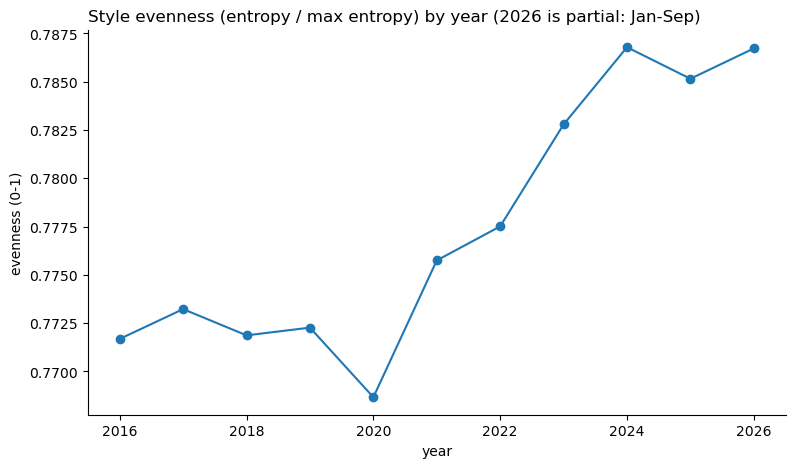

In [8]:
viz.plot_lines(
    entropy, "year", "evenness",
    title="Style evenness (entropy / max entropy) by year (2026 is partial: Jan-Sep)",
    ylabel="evenness (0-1)",
)

## 4. Style co-occurrence networks

In [9]:
cooc = trends.style_cooccurrence(release_styles, min_count=50).cache()
cooc.where(F.col("year") == config.LAST_FULL_YEAR).orderBy(F.desc("jaccard")).show(20, truncate=False)

+----+------------------+-----------------+------+-----+-----+-------------------+
|year|style_a           |style_b          |n_both|n_a  |n_b  |jaccard            |
+----+------------------+-----------------+------+-----+-----+-------------------+
|2025|Health-Fitness    |Therapy          |54    |68   |84   |0.5510204081632653 |
|2025|Health-Fitness    |Special Effects  |60    |68   |115  |0.4878048780487805 |
|2025|Bollywood         |Hindustani       |54    |108  |78   |0.4090909090909091 |
|2025|Special Effects   |Therapy          |56    |115  |84   |0.3916083916083916 |
|2025|Footwork          |Juke             |66    |178  |98   |0.3142857142857143 |
|2025|Score             |Soundtrack       |912   |1236 |3057 |0.26974267968056787|
|2025|Orchestra         |Symphony         |89    |321  |143  |0.23733333333333334|
|2025|Concerto          |Orchestra        |93    |185  |321  |0.22518159806295399|
|2025|Chamber Music     |String Ensemble  |73    |268  |138  |0.21921921921921922|
|202

In [10]:
graph_stats = trends.cooccurrence_graph_stats(cooc)
graph_stats

,year,n_nodes,n_edges,density,n_components,largest_component_share,modularity
0,2016,298,2048,0.046279,2,0.989933,0.637724
1,2017,303,2042,0.044631,3,0.980198,0.652246
2,2018,299,2030,0.045566,2,0.993311,0.645559
3,2019,294,1989,0.046180,3,0.986395,0.630348
4,2020,303,2132,0.046598,2,0.993399,0.620486
5,2021,310,2096,0.043762,2,0.993548,0.627427
6,2022,311,1943,0.040307,2,0.993569,0.624942
7,2023,321,1845,0.035923,2,0.993769,0.657754
8,2024,306,1670,0.035787,3,0.986928,0.665157
9,2025,300,1530,0.034114,5,0.973333,0.675890


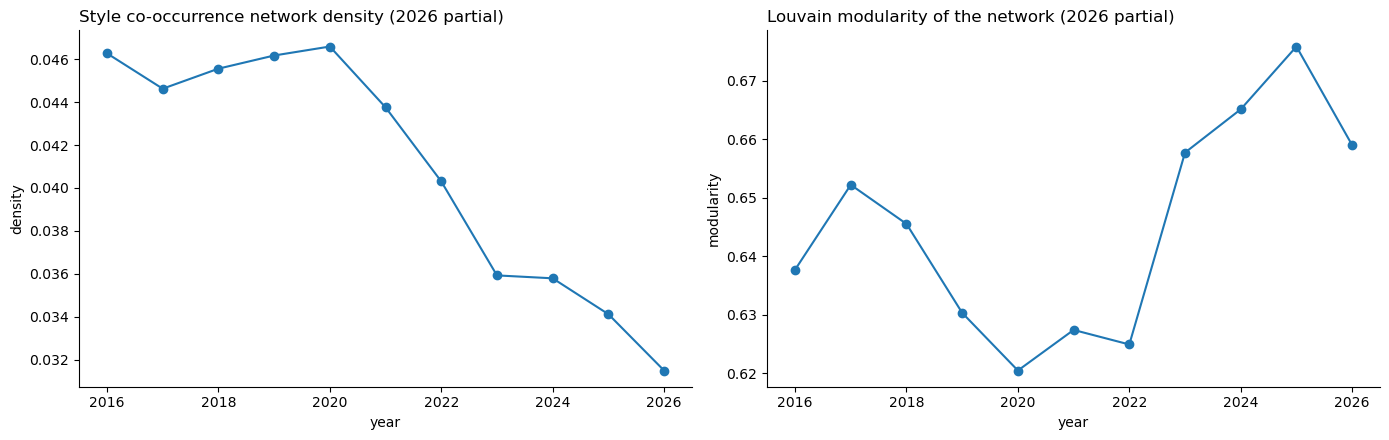

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
viz.plot_lines(graph_stats, "year", "density", title="Style co-occurrence network density (2026 partial)", ax=axes[0])
viz.plot_lines(graph_stats, "year", "modularity", title="Louvain modularity of the network (2026 partial)", ax=axes[1])
fig.tight_layout()

Edges are kept at `min_count=50` releases per year, an absolute threshold. Years with fewer releases keep fewer edges, so compare `density` and `n_nodes` across years with similar release counts, and treat 2026 as partial.

## 5. Fragmentation: new styles or evener use of old ones?

Reading rule for `entropy_decomposition`:

- `entropy_base_tags` is the entropy over only the styles that already existed in the base year (2016), renormalized.
- If `entropy_base_tags` rises along with `entropy`, the change comes from evener use of old styles.
- If `entropy_base_tags` stays flat while `entropy` rises, the change comes from new styles appearing. `n_new_tags` and `new_tag_pair_share` show how many there are and how much of the tagging they carry.

In [12]:
decomp = trends.entropy_decomposition(release_styles, tag_col="style", base_year=2016).toPandas()
decomp

,year,entropy,evenness,entropy_base_tags,n_new_tags,new_tag_pair_share
0,2016,7.318521,0.771685,7.318521,0,0.000000
1,2017,7.334711,0.773228,7.334141,18,0.000046
2,2018,7.335712,0.771869,7.334924,22,0.000065
3,2019,7.331814,0.772269,7.330782,21,0.000092
4,2020,7.300678,0.768666,7.298833,21,0.000232
5,2021,7.353934,0.775749,7.352079,19,0.000230
6,2022,7.381598,0.777513,7.379303,22,0.000284
7,2023,7.437936,0.782789,7.434684,24,0.000498
8,2024,7.456988,0.786788,7.453531,18,0.000526
9,2025,7.466649,0.785155,7.462535,29,0.000505


<Axes: title={'left': 'Style entropy: all styles vs styles that existed in 2016 (2026 partial)'}, xlabel='year', ylabel='Shannon entropy (bits)'>

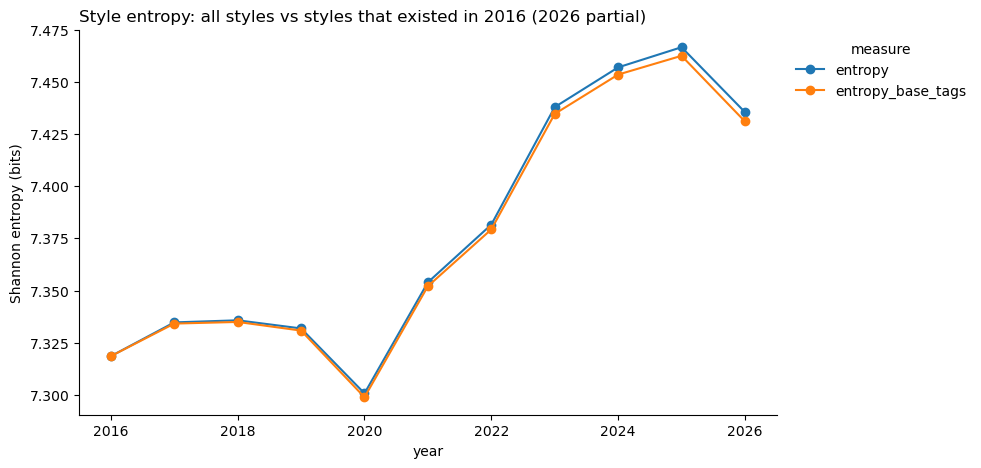

In [13]:
bits = decomp.melt(id_vars="year", value_vars=["entropy", "entropy_base_tags"], var_name="measure", value_name="bits")
viz.plot_lines(
    bits, "year", "bits", "measure",
    title="Style entropy: all styles vs styles that existed in 2016 (2026 partial)",
    ylabel="Shannon entropy (bits)",
)

## 6. Sensitivity to undercounted years

Recent years have fewer catalogued releases, and 2026 is partial. `entropy_sensitivity` redraws, for every year, random samples of the same size (the smallest full year in 2016-`config.LAST_FULL_YEAR`) and recomputes evenness. Evenness depends on sample size, so compare the shape of the sampled line (and its min-max band) with the full-data line, not their levels. If both change by the same amount between years, the trend is not an effect of sample size. If only the full-data line moves, it is. A year with no more releases than the sample size is used whole, so its sampled values equal the full-data value.

In [14]:
sensitivity = trends.entropy_sensitivity(release_styles, releases, tag_col="style", n_draws=5, seed=42).toPandas()
sensitivity

,year,evenness_full,evenness_sub_mean,evenness_sub_min,evenness_sub_max
0,2016,0.771685,0.773007,0.772196,0.773757
1,2017,0.773228,0.774393,0.774041,0.774991
2,2018,0.771869,0.773566,0.773204,0.774114
3,2019,0.772269,0.774180,0.773804,0.774740
4,2020,0.768666,0.770555,0.769836,0.771290
5,2021,0.775749,0.776803,0.775982,0.777618
6,2022,0.777513,0.778471,0.778059,0.779017
7,2023,0.782789,0.783600,0.783077,0.784160
8,2024,0.786788,0.787021,0.786914,0.787216
9,2025,0.785155,0.785155,0.785155,0.785155


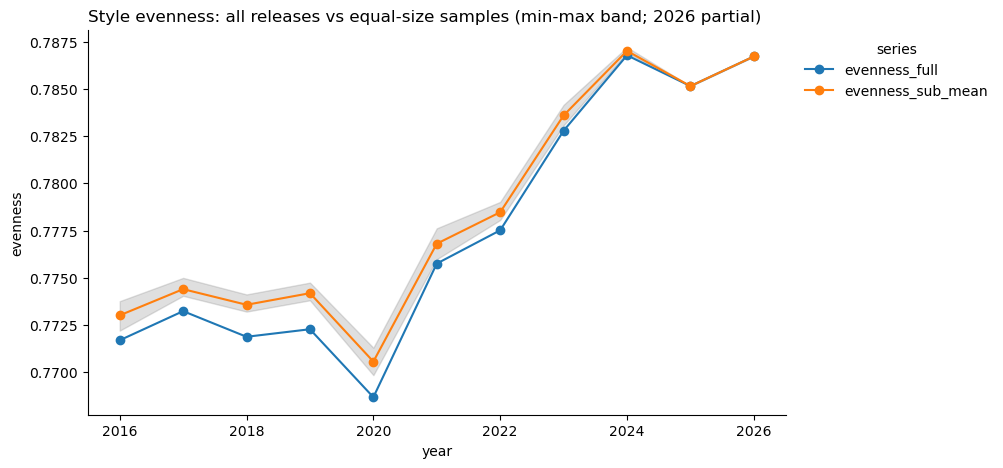

In [15]:
lines = sensitivity.melt(id_vars="year", value_vars=["evenness_full", "evenness_sub_mean"], var_name="series", value_name="evenness")
ax = viz.plot_lines(
    lines, "year", "evenness", "series",
    title="Style evenness: all releases vs equal-size samples (min-max band; 2026 partial)",
)
ax.fill_between(sensitivity["year"], sensitivity["evenness_sub_min"], sensitivity["evenness_sub_max"], alpha=0.25, color="grey")

## Decisions to carry into `main.ipynb`

Fill this in when the exploration is done. Each line should end up as a sentence in the report's methodology or limitations.

- [ ] Use entropy or evenness as the headline fragmentation number, and why.
- [ ] End year for trend comparisons (2024, or later if lag is small).
- [ ] The five to eight styles worth plotting in the report.
- [ ] `min_count` threshold for co-occurrence edges.